<div style="background:linear-gradient(135deg,#0f172a 0%,#1e3a8a 55%,#2a78d6 100%);padding:34px 36px;border-radius:14px;color:#ffffff;font-family:Helvetica,Arial,sans-serif">
  <div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.8">World Bank · World Development Indicators · Case study</div>
  <div style="font-size:34px;font-weight:700;margin:10px 0 6px">🎒 Do Richer Countries Keep More Children in School?</div>
  <div style="font-size:16px;opacity:.9">Wealth, public spending and out-of-school rates across 217 economies, 2000–2025</div>
  <div style="margin-top:18px;font-size:14px">
    <span style="background:rgba(255,255,255,.16);padding:5px 12px;border-radius:20px;margin-right:6px">👤 Mihail Deligrozev</span>
    <span style="background:rgba(255,255,255,.16);padding:5px 12px;border-radius:20px;margin-right:6px">🐍 pandas · matplotlib · SciPy</span>
    <span style="background:rgba(255,255,255,.16);padding:5px 12px;border-radius:20px">📅 Data updated Oct 2026</span>
  </div>
</div>

## 🧭 Executive summary


<table style="width:100%;border-collapse:separate;border-spacing:10px 0">
<tr>
<td style="background:#eaf3fd;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#2a78d6">−0.59</div><div style="color:#333">Rank correlation of GDP per capita with adolescents out of school, 2015 (n = 62)</div></td>
<td style="background:#eaf3fd;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#2a78d6">20× </div><div style="color:#333">Median out-of-school rate for adolescents in the poorest vs richest quarter of countries (20.3% vs 1.0%)</div></td>
<td style="background:#fdf0ea;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#eb6834">≈ 0</div><div style="color:#333">Link between spending effort and out-of-school rates once GDP is held constant</div></td>
<td style="background:#fdf0ea;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#eb6834">35% → 42%</div><div style="color:#333">Adolescents out of school in low-income countries, 2013 to 2024</div></td>
</tr></table>

**Question.** Are children and adolescents more likely to be out of school in poorer countries, and does higher government spending per student help?

**Data.** A fresh World Bank DataBank export of five World Development Indicators for 217 economies, 1960–2025 (last updated 8 October 2026).

**Answer.** Wealth is strongly linked to keeping children in school (**H1 supported**, in every year tested and in a 136-country sample from 2021). Spending effort, measured as spending per student relative to GDP per capita, shows a weak raw link that **disappears once wealth is held constant** (**H2 not supported** on this measure).

**Data-quality catches.** The export has `..` for missing values and footer lines, mixes 5 aggregates with the 217 economies, and its "metadata" file is the data again plus a definitions block. Spending data ends in **2018**, which limits any joint test to 2018 or earlier.


*Originally Assignment 1 (Data Collection and Wrangling) of EPA-1316 Introduction to Urban Data Science, TU Delft. Rebuilt as a standalone case study on a fresh WDI export (last updated 8 October 2026).*

### 📑 Contents

| # | Section | What happens |
|---|---|---|
| 1 | [⚙️ Setup](#setup) | Libraries, chart style, helper functions |
| 2 | [📥 Load and profile](#load) | Read the DataBank export, check its structure and quality |
| 3 | [🌍 The bigger picture](#trend) | Out-of-school trends by income group, 2000–2024 |
| 4 | [🧪 Hypotheses and year choice](#hypotheses) | H1 and H2, picking a cross-section year |
| 5 | [🧹 Missing data and selection bias](#missing) | What listwise deletion costs us |
| 6 | [📊 Testing the hypotheses](#tests) | Rank correlations, CIs, quartiles, partial correlation |
| 7 | [🛰️ H1 with recent data](#recent) | Wealth vs out-of-school in the latest well-covered year |
| 8 | [🔁 Robustness](#robust) | Same tests across years and with a latest-value window |
| 9 | [🏁 Findings and limitations](#findings) | Answers, caveats, next steps |
| 10 | [💾 Save outputs](#save) | Clean table and figures |

<a id="setup"></a>
## ⚙️ 1. Setup
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>All charts share one style and one colour order (blue, orange, aqua), and every chart is numbered and saved as a PNG, so the findings can point back to <i>Figure N</i>. Small statistics helpers (bootstrap confidence intervals, partial rank correlation) live here so the analysis cells stay short.</div>

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import spearmanr, mannwhitneyu, pearsonr, t as t_dist

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

# 🎨 palette and chart style
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
})

# 📁 paths: works locally (./data) and on Kaggle (/kaggle/input/...)
def find_file(pattern):
    for base in [Path("data"), Path("."), Path("/kaggle/input")]:
        hits = sorted(base.rglob(pattern)) if base.exists() else []
        if hits:
            return hits[0]
    raise FileNotFoundError(pattern)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("output")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 🖼️ numbered figures, saved as PNG
_FIG = {"n": 0}
def figure_title(fig, text):
    _FIG["n"] += 1
    fig.suptitle(f"Figure {_FIG['n']} · {text}", x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    return _FIG["n"]

def save(fig, name):
    fig.savefig(FIG_DIR / f"fig{_FIG['n']:02d}_{name}.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.show()

usd = FuncFormatter(lambda v, _: f"${v:,.0f}")

# 📐 statistics helpers
def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def spearman_ci(x, y, n_boot=2000, seed=42):
    """Spearman rho with a percentile bootstrap 95% CI."""
    x, y = np.asarray(x), np.asarray(y)
    rho, p = spearmanr(x, y)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), (n_boot, len(x)))
    boots = [spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return rho, p, lo, hi

def partial_spearman(x, y, z):
    """Rank correlation of x and y after removing the linear effect of rank(z) from both."""
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    res = lambda a: a - np.polyval(np.polyfit(rz, a, 1), rz)
    r, _ = pearsonr(res(rx), res(ry))
    n = len(rx)
    p = 2 * t_dist.sf(abs(r) * np.sqrt((n - 3) / (1 - r**2)), n - 3)
    return r, p

print("✅ setup done · figures go to", FIG_DIR)

✅ setup done · figures go to output/figures


<a id="load"></a>
## 📥 2. Load and profile the data

The data is a **World Bank DataBank export** of five World Development Indicators for 217 economies plus 5 regional and income aggregates, 1960 to 2025. Each row is one **country × indicator**, and each year is a column. The export comes as two files:

| File | Contents |
|---|---|
| `…_Data.csv` | The values, with `..` for missing and a short footer (source, last updated) |
| `…_Series - Metadata.csv` | The same values again, followed by a block with each indicator's definition and licence |
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>A DataBank export is not a clean table. Missing values are written as <code>..</code> (pandas reads them as text unless told otherwise), the year columns are named <code>2015 [YR2015]</code>, and five footer lines sit below the data. Fixing these at load time avoids silent errors later, such as a year column stored as strings.</div>

In [2]:
DATA_FILE = find_file("*_Data.csv")
META_FILE = find_file("*Metadata.csv")

raw = pd.read_csv(DATA_FILE, na_values="..")
footer = raw[raw["Series Code"].isna()]
df = raw.dropna(subset=["Series Code"]).copy()
df.columns = [c.split(" [")[0] for c in df.columns]          # "2015 [YR2015]" -> "2015"
YEARS = [c for c in df.columns if c.isdigit()]
ID_COLS = [c for c in df.columns if not c.isdigit()]

print(f"Raw rows: {len(raw):,}  ->  data rows: {len(df):,}  (dropped {len(footer)} footer/blank lines)")
print("Footer text:", [s for s in footer["Country Name"].dropna()])
print(f"Year columns: {YEARS[0]} to {YEARS[-1]} ({len(YEARS)} years), all numeric: {all(df[y].dtype.kind == 'f' for y in YEARS)}")

Raw rows: 1,115  ->  data rows: 1,110  (dropped 5 footer/blank lines)
Footer text: ['Data from database: World Development Indicators', 'Last Updated: 10/08/2026']
Year columns: 1960 to 2025 (66 years), all numeric: True


In [3]:
# The metadata file repeats the data, then has a definitions block starting at a row whose first cell is "Code"
meta_raw = pd.read_csv(META_FILE, header=None, dtype=str, na_values="..")
start = meta_raw.index[meta_raw[0].eq("Code")][0]
DEFINITIONS = (meta_raw.iloc[start + 1:, :4]
               .set_axis(meta_raw.iloc[start, :4].tolist(), axis=1)
               .set_index("Code"))

# Integrity check: is the data part of the metadata file identical to the data file?
meta_data = pd.read_csv(META_FILE, na_values="..", nrows=start - 1).dropna(subset=["Series Code"])
meta_data.columns = [c.split(" [")[0] for c in meta_data.columns]
same = meta_data[YEARS].reset_index(drop=True).equals(df[YEARS].reset_index(drop=True))
print("Data block of the metadata file identical to the data file:", same)

DEFINITIONS[["Indicator Name", "Short definition"]].style.set_properties(**{"text-align": "left", "white-space": "normal"})

Data block of the metadata file identical to the data file: True


,Indicator Name,Short definition
Code,,
SE.SEC.UNER.LO.ZS,Adolescents out of school (% of lower secondary school age),Adolescents out of school are the percentage of lower secondary school age adolescents who are not enrolled in school.
SE.PRM.UNER.ZS,Children out of school (% of primary school age),Children out of school are the percentage of primary-school-age children who are not enrolled in primary or secondary school. Children in the official primary age group that are in preprimary education should be considered out of school.
SE.XPD.PRIM.PC.ZS,"Government expenditure per student, primary (% of GDP per capita)","Government expenditure per student is the average general government expenditure (current, capital, and transfers) per student in the given level of education, expressed as a percentage of GDP per capita."
SE.XPD.SECO.PC.ZS,"Government expenditure per student, secondary (% of GDP per capita)","Government expenditure per student is the average general government expenditure (current, capital, and transfers) per student in the given level of education, expressed as a percentage of GDP per capita."
NY.GDP.PCAP.CD,GDP per capita (current US$),"Gross domestic product is the total income earned through the production of goods and services in an economic territory during an accounting period. It can be measured in three different ways: using either the expenditure approach, the income approach, or the production approach. The core indicator has been divided by the general population to achieve a per capita estimate.This indicator is expressed in current prices, meaning no adjustment has been made to account for price changes over time. This indicator is expressed in United States dollars."


### Countries versus aggregates

DataBank mixes real economies with **aggregates** (income groups and regions). They overlap with the countries they contain, so leaving them in would count the same children twice.

In [4]:
AGGREGATES = {
    "LIC": "Low income", "LMC": "Lower middle income", "LMY": "Low & middle income",
    "LDC": "Least developed countries (UN)", "MNA": "Middle East, North Africa, Afghanistan & Pakistan (excl. high income)",
}
names = df.drop_duplicates("Country Code").set_index("Country Code")["Country Name"]
countries = df[~df["Country Code"].isin(AGGREGATES)]
aggregates = df[df["Country Code"].isin(AGGREGATES)]

profile = pd.Series({
    "Rows (country × indicator)": f"{len(df):,}",
    "Indicators": df["Series Code"].nunique(),
    "Economies": countries["Country Code"].nunique(),
    "Aggregates": aggregates["Country Code"].nunique(),
    "Year columns": f"{YEARS[0]}–{YEARS[-1]}",
    "Share of cells with a value (economies)": f"{countries[YEARS].notna().mean().mean():.1%}",
}, name="value").to_frame()
display(profile)
names.loc[list(AGGREGATES)].to_frame("Aggregate name")

,value
Rows (country × indicator),"1,110"
Indicators,5
Economies,217
Aggregates,5
Year columns,1960–2025
Share of cells with a value (economies),31.6%


,Aggregate name
Country Code,
LIC,Low income
LMC,Lower middle income
LMY,Low & middle income
LDC,Least developed countries: UN classification
MNA,"Middle East, North Africa, Afghanistan & Pakis..."


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>The data is <b>sparse</b>: only about a third of the economy × indicator × year cells hold a value, so choosing a year matters. The five aggregates are all income or regional groups and are removed from every country-level analysis below. The second file's data block is identical to the main file, so it adds only the indicator definitions.</div>

### Which indicator is reported when?
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>A cross-section only works if all five indicators are reported for the same countries in the same year. A heatmap of how many of the 217 economies report each indicator per year shows at a glance which years are usable.</div>

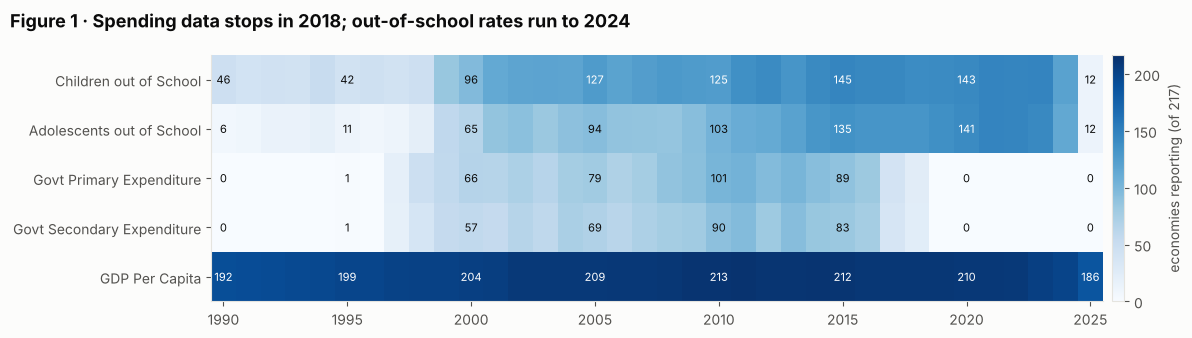

In [5]:
VARIABLES = {
    "SE.PRM.UNER.ZS":    "Children out of School",
    "SE.SEC.UNER.LO.ZS": "Adolescents out of School",
    "SE.XPD.PRIM.PC.ZS": "Govt Primary Expenditure",
    "SE.XPD.SECO.PC.ZS": "Govt Secondary Expenditure",
    "NY.GDP.PCAP.CD":    "GDP Per Capita",
}
SHOW_YEARS = [y for y in YEARS if int(y) >= 1990]
cov = (countries.set_index("Series Code")[SHOW_YEARS].notna()
       .groupby(level=0).sum().loc[list(VARIABLES)].rename(index=VARIABLES))

fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(cov.values, aspect="auto", cmap="Blues", vmin=0, vmax=217)
ax.set_yticks(range(len(cov)), cov.index)
ax.set_xticks(range(0, len(SHOW_YEARS), 5), SHOW_YEARS[::5])
ax.grid(False)
for i, row in enumerate(cov.values):           # label every 5th year so the numbers are readable
    for j in range(0, len(SHOW_YEARS), 5):
        ax.text(j, i, row[j], ha="center", va="center", fontsize=8, color="white" if row[j] > 120 else INK)
fig.colorbar(im, ax=ax, label="economies reporting (of 217)", fraction=.025, pad=.01)
figure_title(fig, "Spending data stops in 2018; out-of-school rates run to 2024")
fig.tight_layout()
save(fig, "coverage_heatmap")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Out-of-school rates are well reported from around 2000 to 2024 (130–150 economies a year), and GDP per capita is almost complete. Spending per student is the bottleneck: it peaks at about 100 economies around 2010–2013, falls sharply after 2016 and is <b>empty from 2019 onwards</b> in this export. Any test that needs spending must use 2018 or earlier, while a test of wealth alone can use recent years (section 7).</div>

<a id="trend"></a>
## 🌍 3. The bigger picture: out-of-school trends by income group
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The aggregates must be kept out of the country analysis, but they are useful on their own: the World Bank computes them with population weights, so they show how the problem has evolved for low- and lower-middle-income countries as a whole. This gives context before zooming into one year.</div>

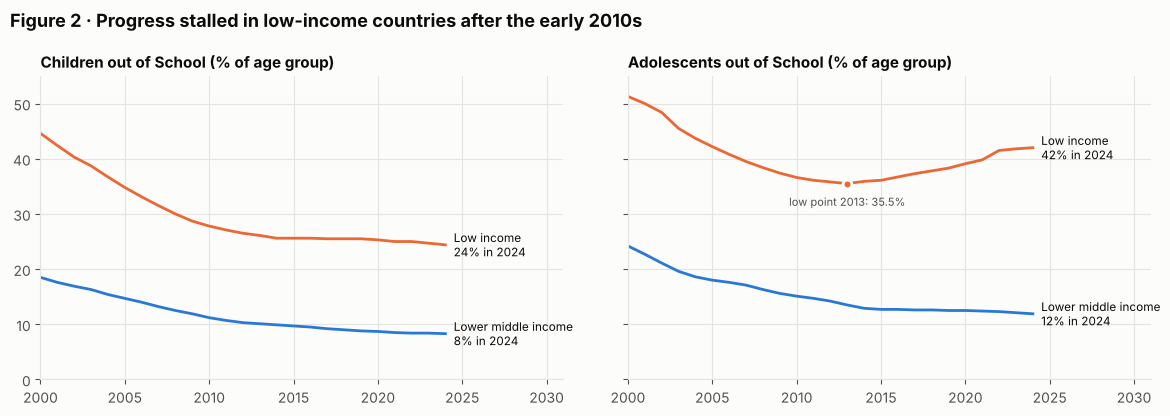

2000  2010  2015  2020  2024
Country Code        Series Code                                            
Low income          Adolescents out of School 51.30 36.60 36.10 39.10 42.00
                    Children out of School    44.60 27.80 25.60 25.30 24.40
Lower middle income Adolescents out of School 24.20 15.10 12.70 12.50 11.90
                    Children out of School    18.50 11.20  9.70  8.70  8.30

In [6]:
trend = (aggregates[aggregates["Country Code"].isin(["LIC", "LMC"])
                    & aggregates["Series Code"].isin(["SE.PRM.UNER.ZS", "SE.SEC.UNER.LO.ZS"])]
         .set_index(["Country Code", "Series Code"])[[y for y in YEARS if 2000 <= int(y) <= 2024]])
yrs = trend.columns.astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, code in zip(axes, ["SE.PRM.UNER.ZS", "SE.SEC.UNER.LO.ZS"]):
    for grp, color in [("LIC", ORANGE), ("LMC", BLUE)]:
        s = trend.loc[(grp, code)]
        ax.plot(yrs, s.values, color=color)
        ax.annotate(f"{AGGREGATES[grp]}\n{s.iloc[-1]:.0f}% in 2024", (yrs[-1], s.iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK)
        lo_year = s.idxmin()
        if grp == "LIC" and code == "SE.SEC.UNER.LO.ZS":
            ax.scatter(int(lo_year), s.min(), s=40, color=color, edgecolor=SURFACE, lw=2, zorder=3)
            ax.annotate(f"low point {lo_year}: {s.min():.1f}%", (int(lo_year), s.min()),
                        xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8, color=MUTED)
    ax.set_title(VARIABLES[code] + " (% of age group)")
    ax.set_xlim(2000, 2031)
    ax.set_ylim(0, 55)
figure_title(fig, "Progress stalled in low-income countries after the early 2010s")
fig.tight_layout()
save(fig, "income_group_trends")

trend.round(1).loc[:, ["2000", "2010", "2015", "2020", "2024"]].rename(index=AGGREGATES | VARIABLES)

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Since 2000 the share of primary-age children out of school in low-income countries fell from 45% to about 25%, but it has been flat since around 2014. For adolescents the picture is worse: the low-income rate bottomed out at <b>35.5% in 2013 and has risen to 42% in 2024</b>, while lower-middle-income countries kept improving slowly (24% → 12%). The gap between the two groups is not closing.</div><div style="background:#fdf0ea;border-left:5px solid #eb6834;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">⚠️ <b>Caution</b><br>These are aggregates published by the World Bank, partly built from imputed country values. They describe the groups, not any single country.</div>

<a id="hypotheses"></a>
## 🧪 4. Hypotheses and choosing a year

I want to understand **why children and adolescents are out of school**, and whether national wealth and public spending explain it.

- **H1:** Countries with higher GDP per capita have lower out-of-school rates.
- **H2:** Countries that spend less per student have higher out-of-school rates.

| Role | Variable | Code |
|---|---|---|
| Outcome | Children out of school (% of primary school age) | `SE.PRM.UNER.ZS` |
| Outcome | Adolescents out of school (% of lower secondary school age) | `SE.SEC.UNER.LO.ZS` |
| Explanatory | Government expenditure per student, primary (% of GDP per capita) | `SE.XPD.PRIM.PC.ZS` |
| Explanatory | Government expenditure per student, secondary (% of GDP per capita) | `SE.XPD.SECO.PC.ZS` |
| Explanatory | GDP per capita (current US$) | `NY.GDP.PCAP.CD` |
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Testing both hypotheses together needs a year in which as many economies as possible report <b>all five</b> indicators. I count complete economies per year and pick by a stated rule, rather than by eye, so the choice is reproducible.</div>

In [7]:
def wide_for(year, frame=countries):
    w = frame.pivot(index="Country Code", columns="Series Code", values=year)
    return w.rename(columns=VARIABLES)[list(VARIABLES.values())]

rows = []
for year in map(str, range(2008, 2019)):
    w = wide_for(year)
    rows.append({"Year": year, **w.notna().sum().to_dict(), "Complete (all 5)": len(w.dropna())})
year_coverage = pd.DataFrame(rows).set_index("Year")

MIN_N = 60
YEAR = max(y for y, n in year_coverage["Complete (all 5)"].items() if n >= MIN_N)
print(f"Rule: most recent year with at least {MIN_N} complete economies  ->  YEAR = {YEAR}")
year_coverage.style.highlight_max("Complete (all 5)", color="#cfe2f8").apply(
    lambda r: ["font-weight:bold" if r.name == YEAR else "" for _ in r], axis=1)

Rule: most recent year with at least 60 complete economies  ->  YEAR = 2015


,Children out of School,Adolescents out of School,Govt Primary Expenditure,Govt Secondary Expenditure,GDP Per Capita,Complete (all 5)
Year,,,,,,
2008,128,86,88,77,211,46
2009,127,93,92,79,213,53
2010,125,103,101,90,213,56
2011,137,110,104,95,214,63
2012,141,112,95,81,212,54
2013,132,120,101,94,212,66
2014,142,131,93,84,213,62
2015,145,135,89,83,212,62
2016,144,132,82,77,211,57


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>2013 has the most complete economies (66), but the rule picks <b>2015</b> (62 economies): the most recent year before spending coverage collapses. 2014 also has 62, and the robustness section repeats every test for 2008–2016, so the choice does not drive the result.</div>

<a id="missing"></a>
## 🧹 5. Missing data and selection bias

Reshaping the chosen year from long to wide gives one row per economy and one column per indicator.
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Out-of-school rates and spending per student come from national education statistics, which not every country reports every year. GDP comes from national accounts, which almost every economy publishes. The outcomes should not be imputed (that would invent the thing I am trying to explain), so I use listwise deletion. Its price is a smaller sample, so I check <b>who drops out</b>.</div>

In [8]:
wide = wide_for(YEAR)
missing = pd.DataFrame({"Missing": wide.isna().sum(), "% missing": wide.isna().mean() * 100})
print(f"{YEAR}: {wide.shape[0]} economies × {wide.shape[1]} indicators")
missing

2015: 217 economies × 5 indicators


,Missing,% missing
Series Code,,
Children out of School,72,33.18
Adolescents out of School,82,37.79
Govt Primary Expenditure,128,58.99
Govt Secondary Expenditure,134,61.75
GDP Per Capita,5,2.30


In [9]:
clean = wide.dropna().sort_values("Children out of School", ascending=False)
dropped = wide.drop(clean.index)
gdp_kept, gdp_drop = clean["GDP Per Capita"], dropped["GDP Per Capita"].dropna()
u, p_mw = mannwhitneyu(gdp_kept, gdp_drop)

pd.DataFrame({
    "Economies": [len(clean), len(dropped)],
    "with GDP data": [gdp_kept.size, gdp_drop.size],
    "Median GDP per capita (US$)": [gdp_kept.median(), gdp_drop.median()],
}, index=["Kept (all 5)", "Dropped"]).style.format({"Median GDP per capita (US$)": "${:,.0f}"}).set_caption(
    f"Mann-Whitney U test on GDP per capita, kept vs dropped: p = {fmt_p(p_mw)}")

,Economies,with GDP data,Median GDP per capita (US$)
Kept (all 5),62,62,"$13,378"
Dropped,155,150,"$4,552"


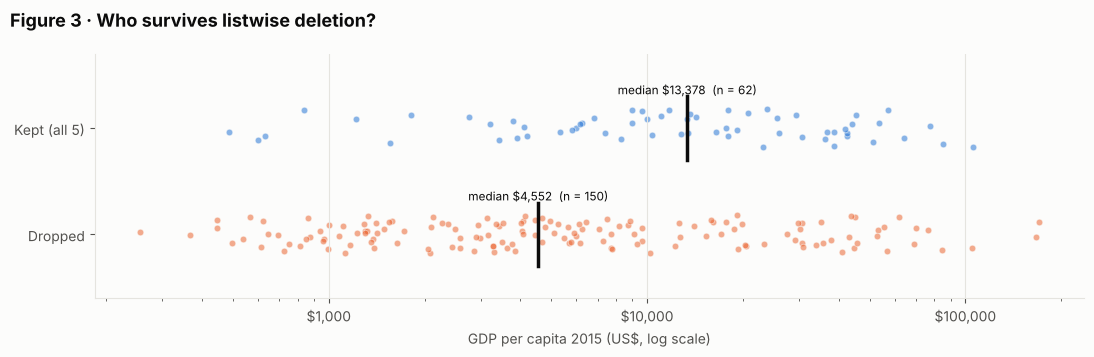

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.6))
rng = np.random.default_rng(1)
for i, (label, s, color) in enumerate([("Dropped", gdp_drop, ORANGE), ("Kept (all 5)", gdp_kept, BLUE)]):
    jitter = i + rng.uniform(-.18, .18, len(s))
    ax.scatter(s, jitter, s=22, alpha=.55, color=color, edgecolor=SURFACE, lw=.6)
    ax.plot([s.median()] * 2, [i - .3, i + .3], color=INK, lw=2.5)
    ax.annotate(f"median ${s.median():,.0f}  (n = {len(s)})", (s.median(), i + .32), fontsize=8.5, color=INK, ha="center")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(usd)
ax.set_yticks([0, 1], ["Dropped", "Kept (all 5)"])
ax.set_ylim(-.6, 1.7)
ax.set_xlabel(f"GDP per capita {YEAR} (US$, log scale)")
ax.grid(axis="y", visible=False)
figure_title(fig, "Who survives listwise deletion?")
fig.tight_layout()
save(fig, "selection_bias")

<div style="background:#fdf0ea;border-left:5px solid #eb6834;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">⚠️ <b>Caution</b><br>Only 62 of 217 economies report all five indicators in 2015, and they are about <b>three times richer</b> (median GDP per capita $13,378 vs $4,552 for those dropped; Mann-Whitney p < 0.001). Many of the poorest countries drop out (Burundi, Central African Republic, Madagascar, Somalia, DR Congo, Malawi, Afghanistan…), exactly where out-of-school rates are highest. Conclusions apply to <i>countries that report all five indicators</i>, not to the whole world, and the wealth effect is probably <b>understated</b> because the poor tail is thin.</div>

<a id="tests"></a>
## 📊 6. Testing the hypotheses
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The variables are heavily skewed: GDP per capita spans more than two orders of magnitude and most out-of-school rates are close to zero. <b>Spearman rank correlation</b> is not distorted by those outliers. With about 60 countries a single coefficient can be noisy, so each one gets a <b>bootstrap 95% confidence interval</b> (2,000 resamples).</div>

In [11]:
TESTS = [
    ("GDP Per Capita",             "Children out of School",    "H1"),
    ("GDP Per Capita",             "Adolescents out of School", "H1"),
    ("Govt Primary Expenditure",   "Children out of School",    "H2"),
    ("Govt Secondary Expenditure", "Adolescents out of School", "H2"),
]
def run_tests(data):
    out = []
    for x, y, h in TESTS:
        rho, p, lo, hi = spearman_ci(data[x], data[y])
        out.append({"Hypothesis": h, "Explanatory": x, "Outcome": y, "rho": rho,
                    "CI low": lo, "CI high": hi, "p-value": fmt_p(p), "n": len(data)})
    return pd.DataFrame(out)

results = run_tests(clean)
results

,Hypothesis,Explanatory,Outcome,rho,CI low,CI high,p-value,n
0,H1,GDP Per Capita,Children out of School,-0.53,-0.74,-0.28,< 0.001,62
1,H1,GDP Per Capita,Adolescents out of School,-0.59,-0.77,-0.35,< 0.001,62
2,H2,Govt Primary Expenditure,Children out of School,-0.32,-0.55,-0.06,0.011,62
3,H2,Govt Secondary Expenditure,Adolescents out of School,-0.03,-0.29,0.25,0.843,62


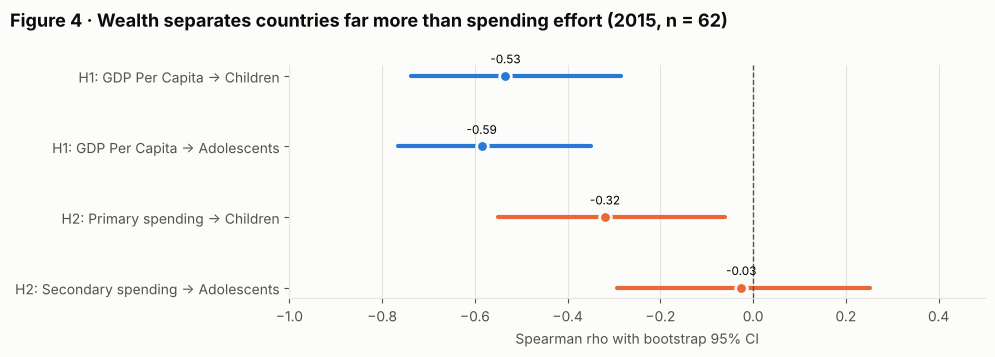

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = [f"{h}: {x.replace('Govt ', '').replace(' Expenditure', ' spending')} → {y.split(' out')[0]}"
          for h, x, y in zip(results["Hypothesis"], results["Explanatory"], results["Outcome"])]
ys = np.arange(len(results))[::-1]
for yy, (_, r) in zip(ys, results.iterrows()):
    color = BLUE if r["Hypothesis"] == "H1" else ORANGE
    ax.plot([r["CI low"], r["CI high"]], [yy, yy], color=color, lw=3, solid_capstyle="round")
    ax.scatter(r["rho"], yy, s=70, color=color, edgecolor=SURFACE, lw=2, zorder=3)
    ax.annotate(f"{r['rho']:.2f}", (r["rho"], yy), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5)
ax.axvline(0, color=MUTED, lw=1, ls="--")
ax.set_yticks(ys, labels)
ax.set_xlim(-1, .5)
ax.set_xlabel("Spearman rho with bootstrap 95% CI")
ax.grid(axis="y", visible=False)
figure_title(fig, f"Wealth separates countries far more than spending effort ({YEAR}, n = {len(clean)})")
fig.tight_layout()
save(fig, "forest_spearman")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Both wealth correlations are moderate to strong and their confidence intervals stay well away from zero. Primary spending effort has a weaker negative link (rho = −0.32, CI −0.55 to −0.06) and secondary spending effort has none (rho = −0.03, CI crosses zero). The scatter plots below show why: the countries with most children out of school (Mali, Niger, Burkina Faso, Côte d'Ivoire, Mauritania) are all below $2,000 per capita, but their spending effort sits in the same 10–25% range as rich countries.</div>

### What the relationships look like

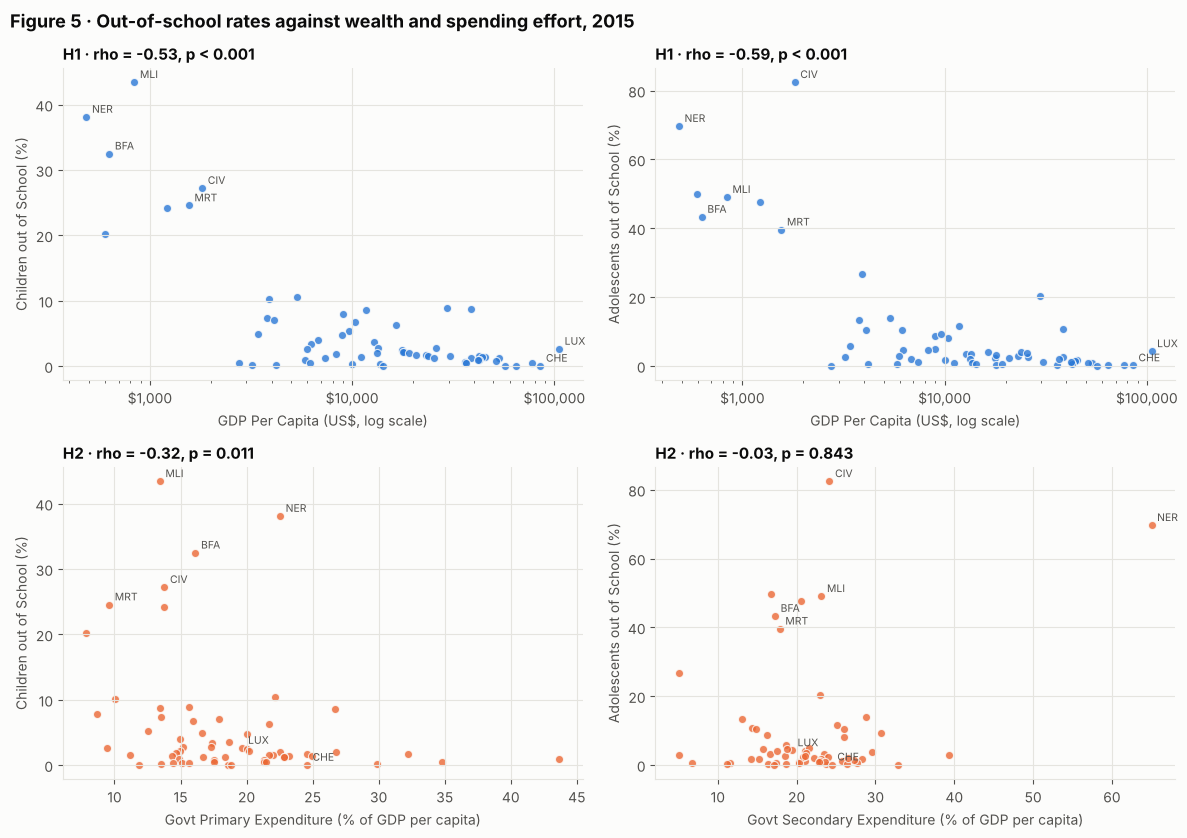

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
label_codes = list(clean.index[:5]) + list(clean.sort_values("GDP Per Capita").index[-2:])
for ax, (x, y, h) in zip(axes.ravel(), TESTS):
    color = BLUE if h == "H1" else ORANGE
    rho, p = spearmanr(clean[x], clean[y])
    ax.scatter(clean[x], clean[y], s=34, alpha=.8, color=color, edgecolor=SURFACE, lw=.8)
    if x == "GDP Per Capita":
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(usd)
    for code in label_codes:
        ax.annotate(code, (clean.loc[code, x], clean.loc[code, y]), xytext=(4, 3),
                    textcoords="offset points", fontsize=7.5, color=MUTED)
    ax.set_xlabel(x + (" (US$, log scale)" if x == "GDP Per Capita" else " (% of GDP per capita)"))
    ax.set_ylabel(y + " (%)")
    ax.set_title(f"{h} · rho = {rho:.2f}, p {'< 0.001' if p < .001 else '= ' + format(p, '.3f')}")
figure_title(fig, f"Out-of-school rates against wealth and spending effort, {YEAR}")
fig.tight_layout()
save(fig, "scatter_panels")

### From a coefficient to something readable: GDP quartiles
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>A rho of −0.6 is abstract. Splitting the countries into four equal groups by GDP per capita and comparing the median out-of-school rate in each group shows the size of the gap in percentage points.</div>

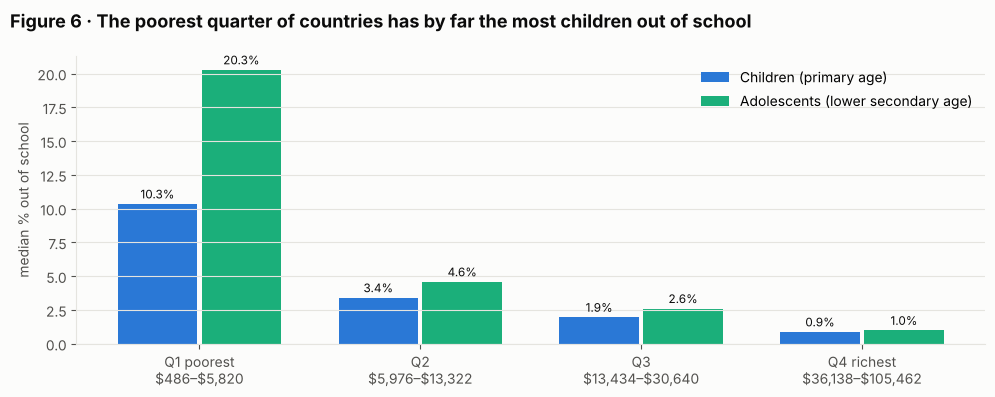

,countries,gdp_range,children,adolescents,primary_effort
GDP quartile,,,,,
Q1 poorest,16,"$486–$5,820",10.34,20.27,14.96
Q2,15,"$5,976–$13,322",3.40,4.58,15.11
Q3,15,"$13,434–$30,640",1.95,2.59,20.00
Q4 richest,16,"$36,138–$105,462",0.87,0.98,20.51


In [14]:
clean["GDP quartile"] = pd.qcut(clean["GDP Per Capita"], 4, labels=["Q1 poorest", "Q2", "Q3", "Q4 richest"])
quart = clean.groupby("GDP quartile", observed=True).agg(
    countries=("GDP Per Capita", "size"),
    gdp_range=("GDP Per Capita", lambda s: f"${s.min():,.0f}–${s.max():,.0f}"),
    children=("Children out of School", "median"),
    adolescents=("Adolescents out of School", "median"),
    primary_effort=("Govt Primary Expenditure", "median"),
)

fig, ax = plt.subplots(figsize=(10, 4))
xpos, w = np.arange(len(quart)), .36
for off, col, color, lab in [(-w / 2 - .01, "children", BLUE, "Children (primary age)"),
                             (w / 2 + .01, "adolescents", AQUA, "Adolescents (lower secondary age)")]:
    bars = ax.bar(xpos + off, quart[col], w, color=color, label=lab)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8.5, padding=2, color=INK)
ax.set_xticks(xpos, [f"{q}\n{r}".replace("$", r"\$") for q, r in zip(quart.index, quart["gdp_range"])])
ax.set_ylabel("median % out of school")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
figure_title(fig, "The poorest quarter of countries has by far the most children out of school")
fig.tight_layout()
save(fig, "gdp_quartiles")
quart

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>In the poorest quarter of countries (GDP per capita below about $5,800) the median adolescent out-of-school rate is <b>20.3%</b>; in the richest quarter it is <b>1.0%</b>. The drop is steep between Q1 and Q2 and flat after that, so the wealth effect is concentrated among the poorest countries. Median primary spending effort is lower in the two poorer quartiles (about 15% of GDP per capita) than in the two richer ones (about 20%), which is why spending effort and out-of-school rates correlate at all.</div>

### Does spending matter once wealth is held constant?
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The two spending indicators are a <b>share of GDP per capita</b>: they measure effort, not money. H2 may be about absolute money, which I can rebuild as <i>% of GDP per capita × GDP per capita</i>. But absolute spending moves almost one-for-one with wealth, so the honest test is a <b>partial rank correlation</b>: the link between spending and out-of-school rates after removing what GDP per capita explains in both.</div>

In [15]:
clean["Primary spend per student (US$)"] = clean["Govt Primary Expenditure"] / 100 * clean["GDP Per Capita"]
clean["Secondary spend per student (US$)"] = clean["Govt Secondary Expenditure"] / 100 * clean["GDP Per Capita"]

rows = []
for spend, outcome in [("Govt Primary Expenditure", "Children out of School"),
                       ("Govt Secondary Expenditure", "Adolescents out of School"),
                       ("Primary spend per student (US$)", "Children out of School"),
                       ("Secondary spend per student (US$)", "Adolescents out of School")]:
    rho, p = spearmanr(clean[spend], clean[outcome])
    pr, pp = partial_spearman(clean[spend], clean[outcome], clean["GDP Per Capita"])
    rows.append({"Spending measure": spend, "Outcome": outcome,
                 "rho": rho, "p": fmt_p(p), "partial rho | GDP": pr, "partial p": fmt_p(pp)})
rows.append({"Spending measure": "Primary spend per student (US$)", "Outcome": "GDP Per Capita",
             "rho": spearmanr(clean["Primary spend per student (US$)"], clean["GDP Per Capita"])[0],
             "p": "", "partial rho | GDP": np.nan, "partial p": ""})
pd.DataFrame(rows)

,Spending measure,Outcome,rho,p,partial rho | GDP,partial p
0,Govt Primary Expenditure,Children out of School,-0.32,0.011,-0.18,0.175
1,Govt Secondary Expenditure,Adolescents out of School,-0.03,0.843,0.11,0.379
2,Primary spend per student (US$),Children out of School,-0.56,< 0.001,-0.22,0.083
3,Secondary spend per student (US$),Adolescents out of School,-0.55,< 0.001,0.10,0.428
4,Primary spend per student (US$),GDP Per Capita,0.97,,NaN,


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Measured as effort, spending has a weak link with children out of school (rho = −0.32) and none with adolescents. Measured in dollars, the link looks strong (rho ≈ −0.55), but dollar spending per student is almost a restatement of wealth (rho = 0.97 with GDP per capita). Holding GDP constant, <b>none of the four spending measures has a significant link</b> left (partial rho −0.22 to 0.11, all p > 0.08). On this data, spending does not explain out-of-school rates beyond what national wealth already explains.</div>

<a id="recent"></a>
## 🛰️ 7. H1 with recent data
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Spending data ends in 2018, but out-of-school rates and GDP run to 2024. H1 needs only those two, so it can be tested on a much larger and more recent sample. This also checks whether the 2015 result still holds a decade later.</div>

In [16]:
h1_cols = ["GDP Per Capita", "Children out of School", "Adolescents out of School"]
h1_cov = pd.Series({y: len(wide_for(y)[h1_cols].dropna()) for y in map(str, range(2018, 2025))}, name="complete economies")
RECENT = h1_cov.idxmax()
recent = wide_for(RECENT)[h1_cols].dropna()
print(f"Best-covered recent year for H1: {RECENT} (n = {len(recent)})")
display(h1_cov.to_frame().T)

recent_results = pd.DataFrame([
    dict(zip(["rho", "p", "CI low", "CI high"], spearman_ci(recent["GDP Per Capita"], recent[y]))) | {"Outcome": y}
    for y in h1_cols[1:]
]).set_index("Outcome")
recent_results["p"] = recent_results["p"].map(fmt_p)
recent_results

Best-covered recent year for H1: 2021 (n = 136)


,2018,2019,2020,2021,2022,2023,2024
complete economies,125,129,131,136,135,132,105


,rho,p,CI low,CI high
Outcome,,,,
Children out of School,-0.45,< 0.001,-0.58,-0.30
Adolescents out of School,-0.71,< 0.001,-0.79,-0.61


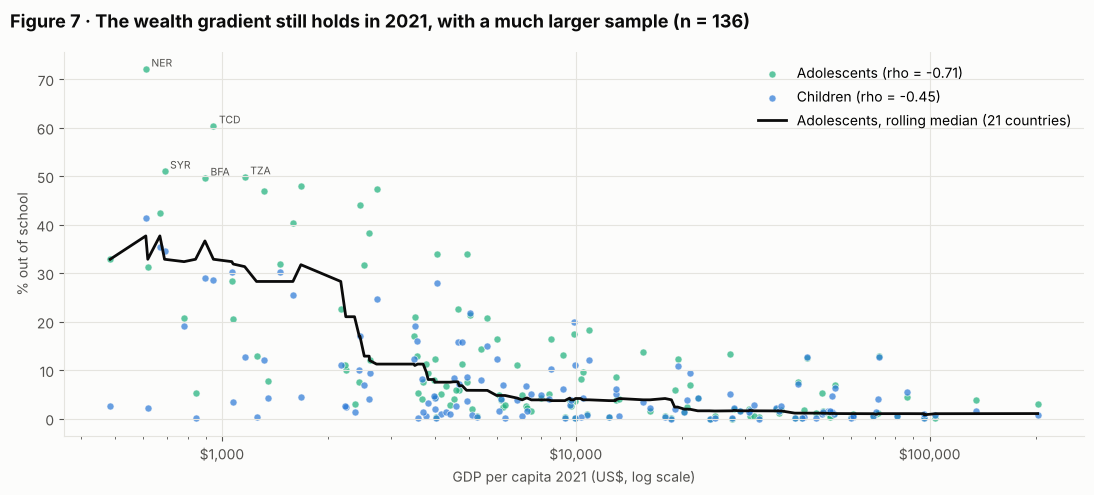

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
for y, color in [("Adolescents out of School", AQUA), ("Children out of School", BLUE)]:
    ax.scatter(recent["GDP Per Capita"], recent[y], s=26, alpha=.7, color=color, edgecolor=SURFACE, lw=.6,
               label=y.replace(" out of School", f" (rho = {spearmanr(recent['GDP Per Capita'], recent[y])[0]:.2f})"))
# rolling median of the adolescent rate along log GDP, to show the shape
srt = recent.sort_values("GDP Per Capita")
roll = srt["Adolescents out of School"].rolling(21, center=True, min_periods=11).median()
ax.plot(srt["GDP Per Capita"], roll, color=INK, lw=2, label="Adolescents, rolling median (21 countries)")
for code in srt.sort_values("Adolescents out of School").index[-5:]:
    ax.annotate(f"{code}", (recent.loc[code, "GDP Per Capita"], recent.loc[code, "Adolescents out of School"]),
                xytext=(4, 2), textcoords="offset points", fontsize=7.5, color=MUTED)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(usd)
ax.set_xlabel(f"GDP per capita {RECENT} (US$, log scale)")
ax.set_ylabel("% out of school")
ax.legend(loc="upper right")
figure_title(fig, f"The wealth gradient still holds in {RECENT}, with a much larger sample (n = {len(recent)})")
fig.tight_layout()
save(fig, "recent_h1")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>With 136 economies in 2021 the wealth gradient is clearer than in 2015: rho = <b>−0.71</b> for adolescents (CI −0.79 to −0.61) and −0.45 for children. The rolling median shows a threshold rather than a straight line: adolescent rates stay around 30% below roughly $2,000 per capita, drop steeply between $2,000 and $4,000, and are close to zero above $20,000. The highest rates are in Niger, Chad, Syria, Burkina Faso and Tanzania.</div>

<a id="robust"></a>
## 🔁 8. Robustness
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The headline numbers come from one year. If they are real, they should look similar in neighbouring years, and when each country's most recent value within a window is used instead of a single year. Both checks use the same four tests.</div>

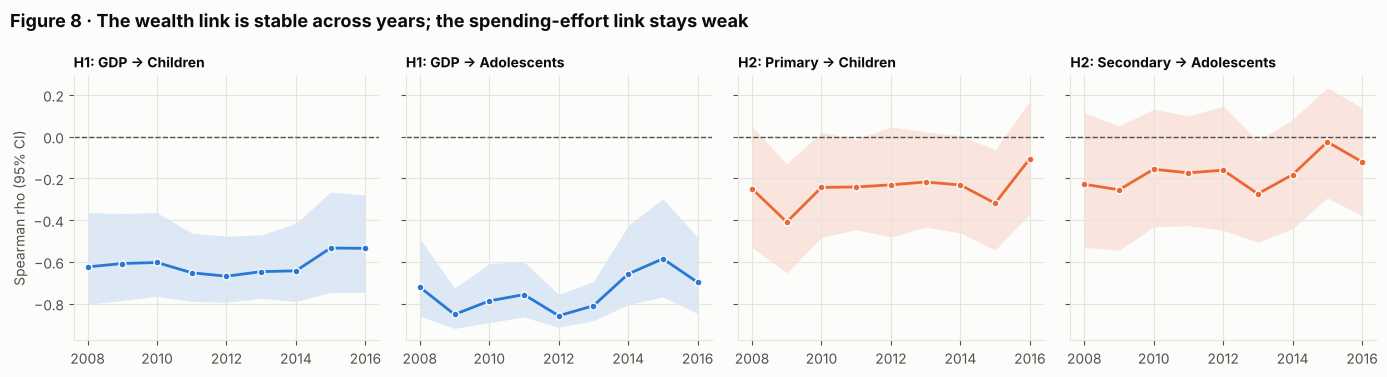

Hypothesis                         H1                                                H2                            n
Outcome     Adolescents out of School Children out of School  Adolescents out of School   Children out of School    
Explanatory            GDP Per Capita         GDP Per Capita Govt Secondary Expenditure Govt Primary Expenditure    
Year                                                                                                                
2008                            -0.72                  -0.62                      -0.23                    -0.25  46
2009                            -0.85                  -0.61                      -0.26                    -0.41  53
2010                            -0.79                  -0.60                      -0.16                    -0.24  56
2011                            -0.76                  -0.65                      -0.17                    -0.24  63
2012                            -0.86                  -0.67                      -0.16                    -0.23  54
2013                            -0.81                  -0.65                      -0.27                    -0.22  66
2014                            -0.66                  -0.64                      -0.18                    -0.23  62
2015                            -0.59                  -0.53                      -0.03                    -0.32  62
2016                            -0.70                  -0.54                      -0.12                    -0.11  57

In [18]:
by_year = []
for year in map(str, range(2008, 2018)):
    w = wide_for(year).dropna()
    if len(w) < 40:
        continue
    r = run_tests(w)
    r["Year"] = int(year)
    by_year.append(r)
by_year = pd.concat(by_year)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, (x, y, h) in zip(axes, TESTS):
    s = by_year[(by_year["Explanatory"] == x) & (by_year["Outcome"] == y)]
    color = BLUE if h == "H1" else ORANGE
    ax.fill_between(s["Year"], s["CI low"], s["CI high"], color=color, alpha=.15, lw=0)
    ax.plot(s["Year"], s["rho"], color=color, marker="o", ms=5, mec=SURFACE)
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.set_title(f"{h}: {x.split(' ')[1] if h == 'H2' else 'GDP'} → {y.split(' ')[0]}", fontsize=10)
    ax.set_xticks(s["Year"][::2])
axes[0].set_ylabel("Spearman rho (95% CI)")
figure_title(fig, "The wealth link is stable across years; the spending-effort link stays weak")
fig.tight_layout()
save(fig, "robustness_years")
by_year.pivot_table(index="Year", columns=["Hypothesis", "Outcome", "Explanatory"], values="rho").round(2).assign(
    n=by_year.groupby("Year")["n"].first())

In [19]:
# Latest value per country and indicator within 2014–2018
WINDOW = [str(y) for y in range(2014, 2019)]
latest = (countries.set_index(["Country Code", "Series Code"])[WINDOW]
          .apply(lambda r: r.dropna().iloc[-1] if r.notna().any() else np.nan, axis=1)
          .unstack().rename(columns=VARIABLES)[list(VARIABLES.values())].dropna())
print(f"Latest value in {WINDOW[0]}–{WINDOW[-1]}: n = {len(latest)} economies (vs {len(clean)} in {YEAR} alone)")
window_results = run_tests(latest)
window_results["partial rho | GDP"] = [
    partial_spearman(latest[x], latest[y], latest["GDP Per Capita"])[0] if h == "H2" else np.nan for x, y, h in TESTS]
window_results["partial p"] = [
    fmt_p(partial_spearman(latest[x], latest[y], latest["GDP Per Capita"])[1]) if h == "H2" else "" for x, y, h in TESTS]
window_results

Latest value in 2014–2018: n = 103 economies (vs 62 in 2015 alone)


,Hypothesis,Explanatory,Outcome,rho,CI low,CI high,p-value,n,partial rho | GDP,partial p
0,H1,GDP Per Capita,Children out of School,-0.61,-0.74,-0.45,< 0.001,103,NaN,
1,H1,GDP Per Capita,Adolescents out of School,-0.75,-0.84,-0.62,< 0.001,103,NaN,
2,H2,Govt Primary Expenditure,Children out of School,-0.34,-0.50,-0.16,< 0.001,103,-0.03,0.794
3,H2,Govt Secondary Expenditure,Adolescents out of School,-0.35,-0.52,-0.17,< 0.001,103,-0.06,0.537


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br><b>H1 holds in every year</b> from 2008 to 2016 (rho −0.53 to −0.86, CIs never near zero), and is strongest for adolescents. H2 is weak and unstable: the primary-effort CI includes zero in most years. Using each country's latest value in 2014–2018 raises the sample to 103 economies; spending effort then correlates at about −0.35 for both outcomes, but the <b>partial correlation given GDP drops to −0.03 and −0.06</b> (p = 0.79 and 0.54). The bigger sample confirms rather than overturns the 2015 result.</div>

<a id="findings"></a>
## 🏁 9. Findings and limitations

**What the data says**

1. **H1 is supported.** Higher GDP per capita goes with lower out-of-school rates for both age groups in every year from 2008 to 2016 (Figure 8), in 2015 (rho = −0.53 for children and −0.59 for adolescents, n = 62; Figure 4) and in 2021 with a much larger sample (rho = −0.45 and −0.71, n = 136; Figure 7). The poorest quarter of countries has a median of 20% of adolescents out of school against 1% in the richest quarter (Figure 6).
2. **H2 is not supported.** Spending per student as a share of GDP per capita shows at most a weak raw link, and **no link at all once wealth is held constant**, both in 2015 (n = 62) and with the latest 2014–2018 values (n = 103). Dollar spending per student is almost the same variable as GDP per capita (rho = 0.97), so it cannot separate money from wealth.
3. **The problem is concentrated and, for adolescents, getting worse.** The relationship looks like a threshold: rates are high below about $2,000 per capita and close to zero above $20,000. In low-income countries the share of adolescents out of school has risen from 35.5% (2013) to 42% (2024) (Figure 2).

**Limitations**

- **Selection bias.** Countries that report all five indicators are about three times richer than those that don't (Figure 3), so the poorest countries are under-represented in the joint tests.
- **No recent spending data.** This export has no spending per student after 2018, so H2 cannot be tested on recent years.
- **Correlation, not causation.** Wealth also goes with health, governance, conflict and geography (several of the highest rates are in the Sahel and in conflict-affected countries), none of which are controlled for.
- **Effort is a ratio.** Spending per student divided by GDP per capita also depends on how many students there are; a country can look generous because few children are enrolled.
- **Data revisions.** The WDI is revised every year. On the previous export, the same 2015 test had 55 countries and rho = −0.70; on this one it has 62 and rho between −0.53 and −0.59. The direction and conclusions did not change.

**Next steps**

- Add income group and region from the WDI country metadata and compare within groups.
- Build a 2008–2018 panel with a regression on log GDP per capita, spending effort and region fixed effects.
- Add conflict and fragility indicators to separate poverty from instability in the Sahel cases.

<a id="save"></a>
## 💾 10. Save outputs

In [20]:
import shutil
out_cols = list(VARIABLES.values()) + ["Primary spend per student (US$)", "Secondary spend per student (US$)", "GDP quartile"]
clean[out_cols].to_csv(OUT_DIR / f"school_dropout_{YEAR}_clean.csv")
recent.to_csv(OUT_DIR / f"school_dropout_{RECENT}_h1.csv")
zip_path = shutil.make_archive(str(OUT_DIR / "figures"), "zip", FIG_DIR)
print("Saved:")
for f in sorted(OUT_DIR.glob("*.csv")) + [Path(zip_path)]:
    print("  ", f)
print(f"   {len(list(FIG_DIR.glob('*.png')))} figures in {FIG_DIR}")

Saved:
   output/school_dropout_2015_clean.csv
   output/school_dropout_2021_h1.csv
   /home/claude/nb/run/output/figures.zip
   8 figures in output/figures


---
*Data: World Bank, World Development Indicators (DataBank export, last updated 8 October 2026), CC BY 4.0.*